In [2]:
print("Welcome to learn how machine unlearning works!")

Welcome to learn how machine unlearning works!


THE PLAN WE WILL BE TRAINIGN AN VIT(VISION TRANSFORMER) IN MNIST THE OG DATASET THEN WE WILL FORGET THE NUMBER 7 WHICH WILL NOT AFFECT THE OTHER NUMBERS THEY WILL BE PREDICTED AS SAME SO THIS IS THE IDEA IN A NUTSHELL 

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
print(torch.cuda.is_available())

cuda
True


In [ ]:
import torch 
from torchvision import datasets
from torchvision.transforms import v2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
print(torch.cuda.is_available())

torch.manual_seed(42)



transform=v2.Compose([ # Compose chains steps together. Each image goes through them in order, like an assembly line
    v2.ToImage(), #Converts the image from a PIL picture to a PyTorch tensor of shape [1, 28, 28]. The values are still whole numbers from 0 to 255.
    v2.ToDtype(torch.float32,scale=True), #torch.float32 changes the whole numbers into decimals, which models need for their math. , scale=True also divides by 255, so 0–255 becomes 0.0–1.0. Without it you'd get 0.0–255.0.
    v2.Normalize(mean=(0.1307,), std=(0.3081,)), #For every pixel it computes (pixel - 0.1307) / 0.3081 , 0.1307 is the average pixel value over all MNIST training images (mostly black background, so it's low). 0.3081 is how spread out the pixel values are (the standard deviation).

])
train_data=datasets.MNIST(root="../data", train=True, download=True, transform=transform)
test_data=datasets.MNIST(root="../data", train=False, download=True, transform=transform)

print("Train images:", len(train_data))
print("Test images:", len(test_data))


cuda
True


100%|██████████| 9.91M/9.91M [00:05<00:00, 1.70MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 108kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 993kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.35MB/s]

Train images: 60000
Test images: 10000


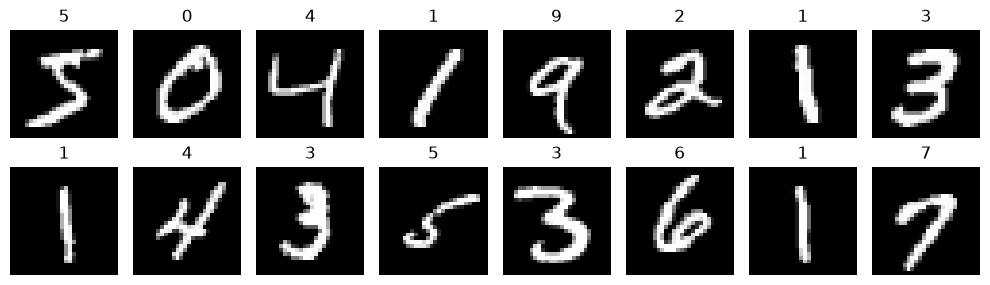

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 8, figsize=(10, 3))   # a grid of 2 rows x 8 images

for i, ax in enumerate(axes.flatten()):
    img, lbl = train_data[i]
    ax.imshow(img.squeeze(0), cmap="gray")   # squeeze(0) removes the channel: [1,28,28] -> [28,28]
    ax.set_title(lbl)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:
image, label = train_data[0]    # each item in the dataset is (image, label)

print("Shape:", image.shape)   # [channels, height, width]
print("Type:", image.dtype)
print("Min value:", image.min().item())
print("Max value:", image.max().item())
print("Label:", label)


Shape: torch.Size([1, 28, 28])
Type: torch.float32
Min value: -0.4242129623889923
Max value: 2.821486711502075
Label: 5


 DataLoaders  

 Why: a model doesn't learn from one image at a time (too slow) or all 60,000 at once (won't fit in GPU memory). It learns from mini-batches, say 128 images at a time. A DataLoader handles this for us: it groups images into batches, shuffles them, and hands them over one batch at a time.

One pass through all 60,000 images is called an epoch. With batches of 128, that's 60000 / 128 ≈ 469 batches per epoch

In [ ]:
from torch.utils.data import DataLoader
BATCH_SIZE = 128 # images per batch; 64-256 is typical for small datasets
train_loader=DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,# new random order every epoch, so the model can't memorize the order
    num_workers=0,# load data in the main process (extra workers often hang in Jupyter on Windows)
    pin_memory=True # faster copying from CPU RAM to the GPU

)
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,      # no need to shuffle for testing; a fixed order keeps results repeatable
    num_workers=0,
    pin_memory=True,
)
print("Train batches per epoch:", len(train_loader))
print("Test batches:", len(test_loader))

# Grab one batch to see its shape
images, labels = next(iter(train_loader))
print("Images batch shape:", images.shape)   # [batch, channels, height, width]
print("Labels batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist()) #First 10 labels: [ ...10 random digits... ]


Train batches per epoch: 469
Test batches: 79
Images batch shape: torch.Size([128, 1, 28, 28])
Labels batch shape: torch.Size([128])
First 10 labels: [1, 2, 8, 5, 2, 6, 9, 9, 9, 4]
